In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE
from sklearn.manifold import Isomap
import umap
from sklearn.manifold import trustworthiness
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [7]:
data = pd.read_pickle('data_mod.pkl')
data.head()

,k1,k2,k3,k4,k5,k6,k7,k9,k10,k11,k12,k13,k14,k15,k16,k17,k18,k19,k20
0,0.403809,0.503518,0.548820,0.328302,0.330954,0.475458,0.833823,0.529053,0.330879,0.414133,0.451272,0.309298,0.359411,0.340312,0.459953,1.000000,0.554562,0.497247,0.479035
1,0.591695,0.653597,0.632007,0.763404,0.169329,0.543158,0.421875,0.903975,0.333300,0.515462,0.471764,0.330484,0.592674,0.566433,0.490934,1.000000,0.678800,0.510526,0.458055
2,0.300968,0.462057,0.341906,0.000000,0.379270,0.893999,1.000000,0.511229,0.284299,0.173041,0.502503,0.083725,0.220906,0.402367,1.000000,0.558105,0.000000,0.371303,0.399927
3,1.000000,1.000000,1.000000,0.902599,0.126387,0.311175,0.433346,0.999822,0.607228,0.489965,0.564472,1.000000,1.000000,0.942774,0.418881,0.546973,0.854628,1.000000,1.000000
4,0.555295,0.464936,0.620328,0.709942,0.235475,1.000000,0.927524,0.752390,0.374004,0.243528,0.407338,0.231825,0.403838,0.317202,0.420597,0.496557,0.516877,0.414231,0.426759


In [8]:
def scorer_func(estimator, data):
    data_scaled = estimator.named_steps['scaler'].transform(data)
    emb = estimator.transform(data)

    return trustworthiness(data_scaled, emb, n_neighbors = 15)

In [9]:
cv = KFold(n_splits = 5, shuffle = True, random_state = 42)

In [16]:
pca = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components = 7))])
pca_scores = cross_val_score(pca, data, scoring = scorer_func, cv = cv)

print(pca_scores.mean())

0.9836383291865018


In [17]:
kpca = Pipeline([('scaler', StandardScaler()), ('kpca', KernelPCA(n_components = 7))])
param_grid_kpca = [
    {
        'kernel': ['rbf'],
        'gamma': [0.00001, 0.00005, 0.0001, 0.0005, 0.001]
    },
    {
        'kernel': ['poly'],
        'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1],
        'degree': [2, 3, 4]
    },
    {
        'kernel': ['sigmoid'],
        'gamma': [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5]
    }
]

param_grid_kpca_pipe = [{f'kpca__{key}': values for key, values in grid.items()} for grid in param_grid_kpca]

grid_search_kernelpca = GridSearchCV(estimator = kpca, param_grid = param_grid_kpca_pipe, scoring = scorer_func, cv = cv)

In [18]:
grid_search_kernelpca.fit(data)
kpca_cv_df = pd.DataFrame(grid_search_kernelpca.cv_results_).sort_values(by = 'mean_test_score', ascending = False)
print(grid_search_kernelpca.best_params_, '\n', grid_search_kernelpca.best_score_)
display(kpca_cv_df[['param_kpca__kernel', 'param_kpca__gamma', 'param_kpca__degree', 'mean_test_score', 'std_test_score', 'rank_test_score']])

{'kpca__gamma': 0.01, 'kpca__kernel': 'sigmoid'} 
 0.9838872349503578


,param_kpca__kernel,param_kpca__gamma,param_kpca__degree,mean_test_score,std_test_score,rank_test_score
29,sigmoid,0.01000,NaN,0.983887,0.001006,1
28,sigmoid,0.00500,NaN,0.983765,0.000918,2
27,sigmoid,0.00100,NaN,0.983692,0.000922,3
6,poly,0.00050,2.0,0.983651,0.000896,4
26,sigmoid,0.00050,NaN,0.983644,0.000936,5
13,poly,0.00050,3.0,0.983639,0.000874,6
7,poly,0.00100,2.0,0.983639,0.000874,6
5,poly,0.00010,2.0,0.983638,0.000910,8
12,poly,0.00010,3.0,0.983636,0.000909,9
0,rbf,0.00001,NaN,0.983631,0.000912,10


In [29]:
res = []
data_scaled = StandardScaler().fit_transform(data)

param_grid_tsne = {
    'n_components': [7],
    'method': ['exact'],
    'perplexity': [5, 15, 30, 50],
    'learning_rate': [50.0, 60.0, 80.0, 100.0],
}

for params in ParameterGrid(param_grid_tsne):
    tsne = TSNE(**params, random_state = 42)
    
    data_emb = tsne.fit_transform(data_scaled)
    score = trustworthiness(data_scaled, data_emb, n_neighbors = 15)
    
    res_entry = {f'param_{k}': v for k, v in params.items()}
    res_entry['train_score'] = score
    res.append(res_entry)

tsne_cv_df = pd.DataFrame(res).sort_values(by = 'train_score', ascending = False)

best_it = tsne_cv_df.iloc[0]
print({k.replace('param_', ''): v for k, v in best_it.items() if k.startswith('param_')})
print(best_it['train_score'])
display(tsne_cv_df)

{'learning_rate': np.float64(50.0), 'method': 'exact', 'n_components': np.int64(7), 'perplexity': np.int64(50)}
0.9921010576250098


,param_learning_rate,param_method,param_n_components,param_perplexity,train_score
3,50.0,exact,7,50,0.992101
11,80.0,exact,7,50,0.991325
15,100.0,exact,7,50,0.990450
14,100.0,exact,7,30,0.990361
10,80.0,exact,7,30,0.990129
7,60.0,exact,7,50,0.990079
6,60.0,exact,7,30,0.989760
2,50.0,exact,7,30,0.989192
9,80.0,exact,7,15,0.987788
1,50.0,exact,7,15,0.987747


In [12]:
isomap = Pipeline([('scaler', StandardScaler()), ('isomap', Isomap(n_components = 7))])

param_grid_isomap = {
    'n_neighbors': [5, 10, 15, 30, 50],
    'metric': ['euclidean', 'manhattan']
}

param_grid_isomap_pipe = {f'isomap__{key}': values for key, values in param_grid_isomap.items()}

grid_search_isomap = GridSearchCV(estimator = isomap, param_grid = param_grid_isomap_pipe, scoring = scorer_func, cv = cv)

In [14]:
grid_search_isomap.fit(data)
isomap_cv_df = pd.DataFrame(grid_search_isomap.cv_results_).sort_values(by = 'mean_test_score', ascending = False)
print(grid_search_isomap.best_params_, '\n', grid_search_isomap.best_score_)
display(isomap_cv_df[['param_isomap__n_neighbors', 'param_isomap__metric', 'mean_test_score', 'std_test_score', 'rank_test_score']])

{'isomap__metric': 'euclidean', 'isomap__n_neighbors': 50} 
 0.982752872819318


,param_isomap__n_neighbors,param_isomap__metric,mean_test_score,std_test_score,rank_test_score
4,50,euclidean,0.982753,0.000728,1
3,30,euclidean,0.980640,0.001137,2
9,50,manhattan,0.980337,0.001011,3
8,30,manhattan,0.978625,0.001346,4
2,15,euclidean,0.976163,0.001777,5
7,15,manhattan,0.973111,0.001742,6
1,10,euclidean,0.971991,0.002060,7
6,10,manhattan,0.968341,0.001902,8
0,5,euclidean,0.962060,0.002214,9
5,5,manhattan,0.958122,0.001497,10


In [27]:
umap_model = Pipeline([('scaler', StandardScaler()), ('umap', umap.UMAP(n_components = 7))])

param_grid_umap = {
    'n_neighbors': [10, 30, 50],
    'min_dist': [0.0, 0.3],
    'metric': ['euclidean', 'manhattan']
}

param_grid_umap_pipe = {f'umap__{key}': values for key, values in param_grid_umap.items()}

grid_search_umap = GridSearchCV(estimator = umap_model, param_grid = param_grid_umap_pipe, scoring = scorer_func, cv = cv)

In [28]:
grid_search_umap.fit(data)
umap_cv_df = pd.DataFrame(grid_search_umap.cv_results_).sort_values(by = 'mean_test_score', ascending = False)
print(grid_search_umap.best_params_, '\n', grid_search_umap.best_score_)
display(umap_cv_df[['param_umap__n_neighbors', 'param_umap__min_dist', 'param_umap__metric', 'mean_test_score', 'std_test_score', 'rank_test_score']])

{'umap__metric': 'euclidean', 'umap__min_dist': 0.3, 'umap__n_neighbors': 50} 
 0.9585429520645468


,param_umap__n_neighbors,param_umap__min_dist,param_umap__metric,mean_test_score,std_test_score,rank_test_score
5,50,0.3,euclidean,0.958543,0.004020,1
4,30,0.3,euclidean,0.956298,0.004057,2
11,50,0.3,manhattan,0.951881,0.001321,3
10,30,0.3,manhattan,0.950013,0.001715,4
3,10,0.3,euclidean,0.949122,0.004621,5
9,10,0.3,manhattan,0.944470,0.002970,6
2,50,0.0,euclidean,0.944042,0.003858,7
1,30,0.0,euclidean,0.941150,0.004153,8
8,50,0.0,manhattan,0.935361,0.002632,9
7,30,0.0,manhattan,0.932610,0.002070,10


In [30]:
X_train, X_test = train_test_split(data, test_size = 0.2, random_state = 42)
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train, dtype = torch.float32)
X_test_tensor = torch.tensor(X_test, dtype = torch.float32)

torch.manual_seed(42)

encoder = nn.Sequential(
    nn.Linear(19, 14),
    nn.ReLU(),
    nn.Linear(14, 7)
)

decoder = nn.Sequential(
    nn.Linear(7, 14),
    nn.ReLU(),
    nn.Linear(14, 19)
)

autoencoder = nn.Sequential(encoder, decoder)

optimizer = torch.optim.Adam(autoencoder.parameters(), lr = 0.001)
criterion = nn.MSELoss()

for epoch in range(200):
    optimizer.zero_grad()

    reconstructed = autoencoder(X_train_tensor)
    loss = criterion(reconstructed, X_train_tensor)

    loss.backward()
    optimizer.step()

autoencoder.eval()
with torch.no_grad():
    enc = encoder(X_test_tensor).numpy()

score = trustworthiness(X_test, enc, n_neighbors = 15)
print(score)

0.9241983192149306


In [51]:
pca.fit(data)
b_pca = pca.transform(data)
b_kpca = grid_search_kernelpca.best_estimator_.transform(data)
b_isomap = grid_search_isomap.best_estimator_.transform(data)
b_umap = grid_search_umap.best_estimator_.transform(data)
tsne =  TSNE(n_components = 7, learning_rate = 50, method = 'exact', perplexity = 50)
b_tsne = tsne.fit_transform(data_scaled)

X_all = scaler.transform(data)
X_all_tensor = torch.tensor(X_all, dtype = torch.float32)

encoder.eval()
with torch.no_grad():
    b_ae = encoder(X_all_tensor).numpy()

In [52]:
embeddings = {
    'PCA': b_pca,
    'Kernel PCA': b_kpca,
    'Isomap': b_isomap,
    'UMAP': b_umap,
    't-SNE': b_tsne,
    'Autoencoder': b_ae
}

for name, elem in embeddings.items():
    print(name, np.asarray(elem).shape)

PCA (2695, 7)
Kernel PCA (2695, 7)
Isomap (2695, 7)
UMAP (2695, 7)
t-SNE (2695, 7)
Autoencoder (2695, 7)


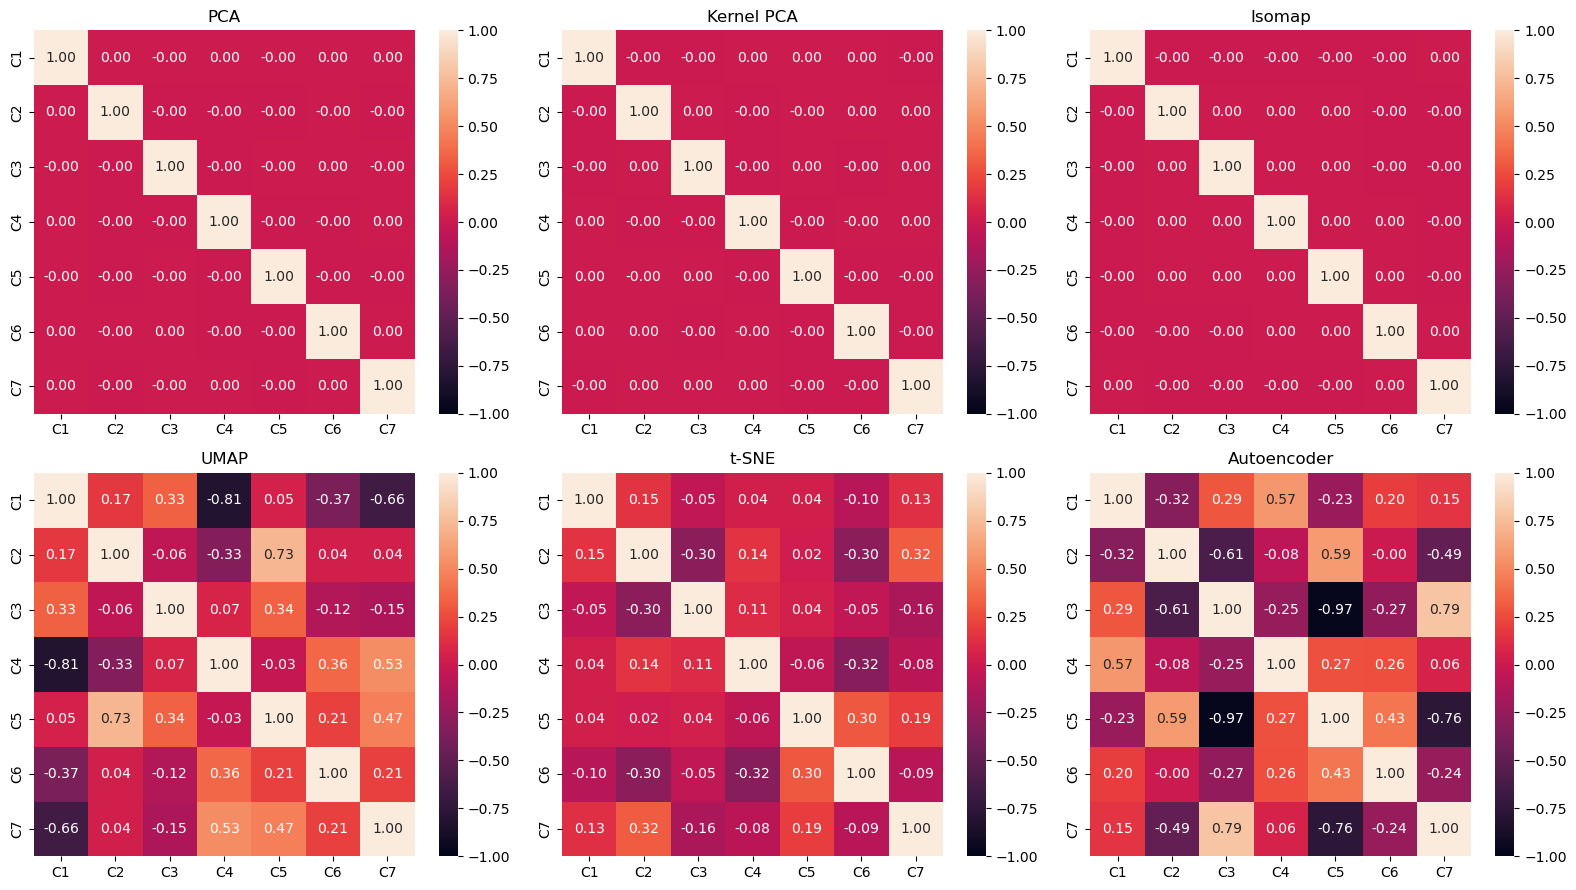

In [53]:
fig, axes = plt.subplots(2, 3, figsize = (16, 9))

for ax, (name, elem) in zip(axes.flat, embeddings.items()):
    elem_df = pd.DataFrame(elem, columns = [f'C{i + 1}' for i in range(7)])

    sns.heatmap(elem_df.corr(), annot = True, fmt = '.2f', vmin = -1, vmax = 1, ax = ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()

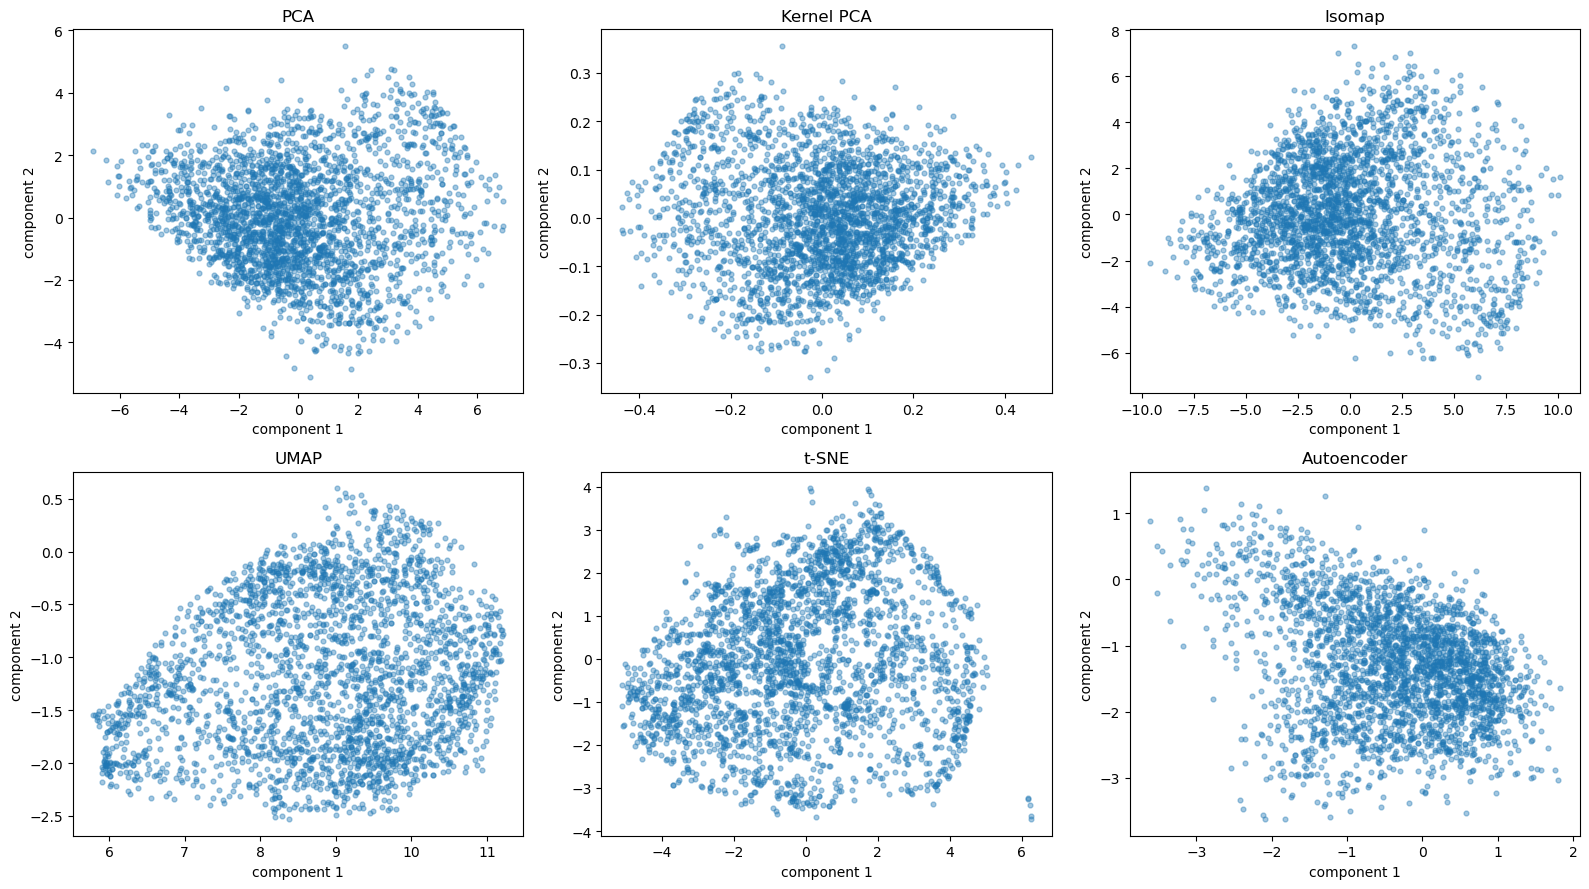

In [54]:
fig, axes = plt.subplots(2, 3, figsize = (16, 9))

for ax, (name, elem) in zip(axes.flat, embeddings.items()):
    elem = np.asarray(elem)
    ax.scatter(elem[:, 0], elem[:, 1], alpha = 0.4, s = 12)

    ax.set_title(name)
    ax.set_xlabel('component 1')
    ax.set_ylabel('component 2')

plt.tight_layout()
plt.show()

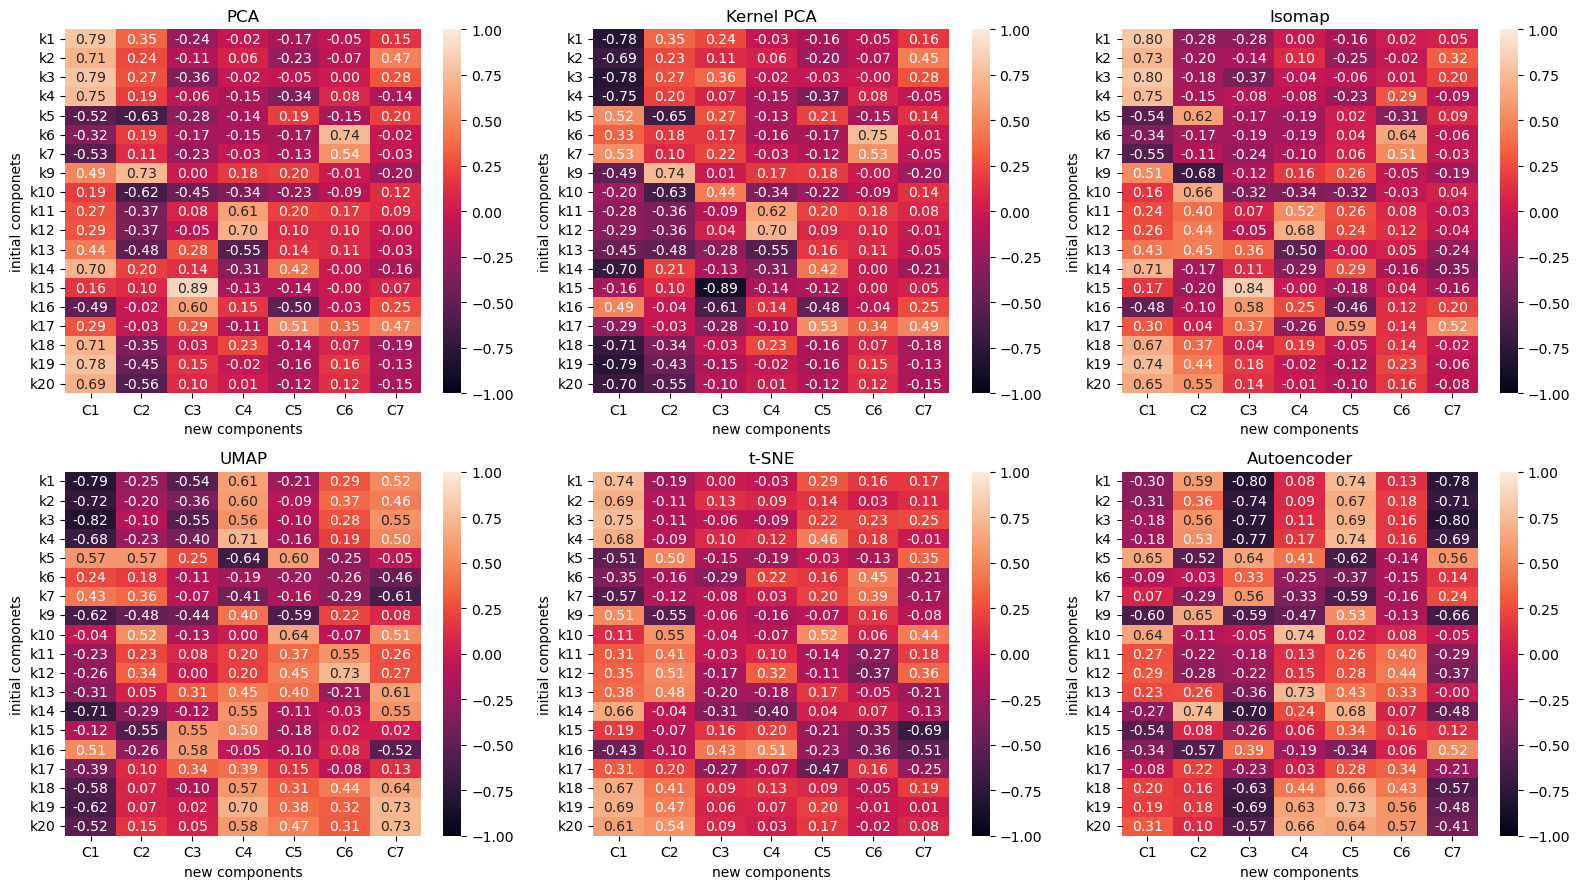

In [55]:
fig, axes = plt.subplots(2, 3, figsize = (16, 9))

for ax, (name, elem) in zip(axes.flat, embeddings.items()):
    elem_df = pd.DataFrame(elem, columns = [f'C{i + 1}' for i in range(7)])
    combined = pd.concat([data.reset_index(drop = True), elem_df], axis = 1)

    corr = combined.corr().loc[data.columns, elem_df.columns]

    sns.heatmap(corr, annot = True, fmt = '.2f', vmin = -1, vmax = 1, ax = ax)
    ax.set_title(name)
    ax.set_xlabel('new components')
    ax.set_ylabel('initial componets')

plt.tight_layout()
plt.show()